In [1]:
import sys
sys.path.append('..')
import torch
from model_batter import MaskedAutoencoderViT
from data.batter import BatterDataset


/path/to/conda/envs/mae/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ckpt = '/path/to/mae/output_dir/checkpoint-399.pth'
checkpoint = torch.load(ckpt, map_location='cuda')

/tmp/ipykernel_999359/3201820536.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(ckpt, map_location='cuda')


In [7]:
from models_vit import vit_batter_patch16 as vit
from util import misc
from torchvision import transforms
import numpy as np

In [4]:
vit_model = vit()
vit_model.load_state_dict(checkpoint['model'], strict=False)

_IncompatibleKeys(missing_keys=[], unexpected_keys=['mask_token', 'decoder_pos_embed', 'decoder_embed.weight', 'decoder_embed.bias', 'decoder_blocks.0.norm1.weight', 'decoder_blocks.0.norm1.bias', 'decoder_blocks.0.attn.qkv.weight', 'decoder_blocks.0.attn.qkv.bias', 'decoder_blocks.0.attn.proj.weight', 'decoder_blocks.0.attn.proj.bias', 'decoder_blocks.0.norm2.weight', 'decoder_blocks.0.norm2.bias', 'decoder_blocks.0.mlp.fc1.weight', 'decoder_blocks.0.mlp.fc1.bias', 'decoder_blocks.0.mlp.fc2.weight', 'decoder_blocks.0.mlp.fc2.bias', 'decoder_blocks.1.norm1.weight', 'decoder_blocks.1.norm1.bias', 'decoder_blocks.1.attn.qkv.weight', 'decoder_blocks.1.attn.qkv.bias', 'decoder_blocks.1.attn.proj.weight', 'decoder_blocks.1.attn.proj.bias', 'decoder_blocks.1.norm2.weight', 'decoder_blocks.1.norm2.bias', 'decoder_blocks.1.mlp.fc1.weight', 'decoder_blocks.1.mlp.fc1.bias', 'decoder_blocks.1.mlp.fc2.weight', 'decoder_blocks.1.mlp.fc2.bias', 'decoder_blocks.2.norm1.weight', 'decoder_blocks.2.norm

In [5]:
vit_model = vit_model.to('cuda')

In [6]:
transform_train = transforms.Compose([
            transforms.ToTensor(),
            # transforms.RandomHorizontalFlip(),
            ])

transform_val = transforms.Compose([
            transforms.ToTensor(),
            ])

dataset_train = BatterDataset(
        data_path='/path/to/mae/data/Battery_data_processed',
        transform=transform_train,
        is_train=True,
        batter='LCO',
        split_ratio=0.8,
    )
    

dataset_val = BatterDataset(
        data_path='/path/to/mae/data/Battery_data_processed',
        transform=transform_val,
        is_train=False,
        batter='LCO',
        split_ratio=0.8,
    )

num_tasks = misc.get_world_size()
global_rank = misc.get_rank()
sampler_train = torch.utils.data.DistributedSampler(
    dataset_train, num_replicas=num_tasks, rank=global_rank, shuffle=True
)

sampler_val = torch.utils.data.SequentialSampler(dataset_val)

data_loader_train = torch.utils.data.DataLoader(
        dataset_train, sampler=sampler_train,
        batch_size=16,
        num_workers=8,
        pin_memory=True,
        drop_last=True,
    )
data_loader_val = torch.utils.data.DataLoader(
        dataset_val, sampler=sampler_val,
        batch_size=1,
        num_workers=1,
        pin_memory=True,
        drop_last=False,
    )


In [11]:
train_feature = []
for i, data in enumerate(data_loader_train):

    images, labels = data
    images = images.float().to('cuda')
    labels = labels.float().to('cuda')
    with torch.no_grad():
        features = vit_model(images).cpu().numpy()
        train_feature.extend(features)
        print(features.shape)
        # features = features.view(features.shape[0], -1)
        
train_feature = np.array(train_feature)

val_feature = []
for i, data in enumerate(data_loader_val):
    images, labels = data
    images = images.float().to('cuda')
    labels = labels.float().to('cuda')
    with torch.no_grad():
        features = vit_model(images).cpu().numpy()
        val_feature.extend(features)
        # features = features.view(features.shape[0], -1)
        
val_feature = np.array(val_feature)
        

(16, 1024)
(16, 1024)


In [13]:
train_feature.shape

(32, 1024)

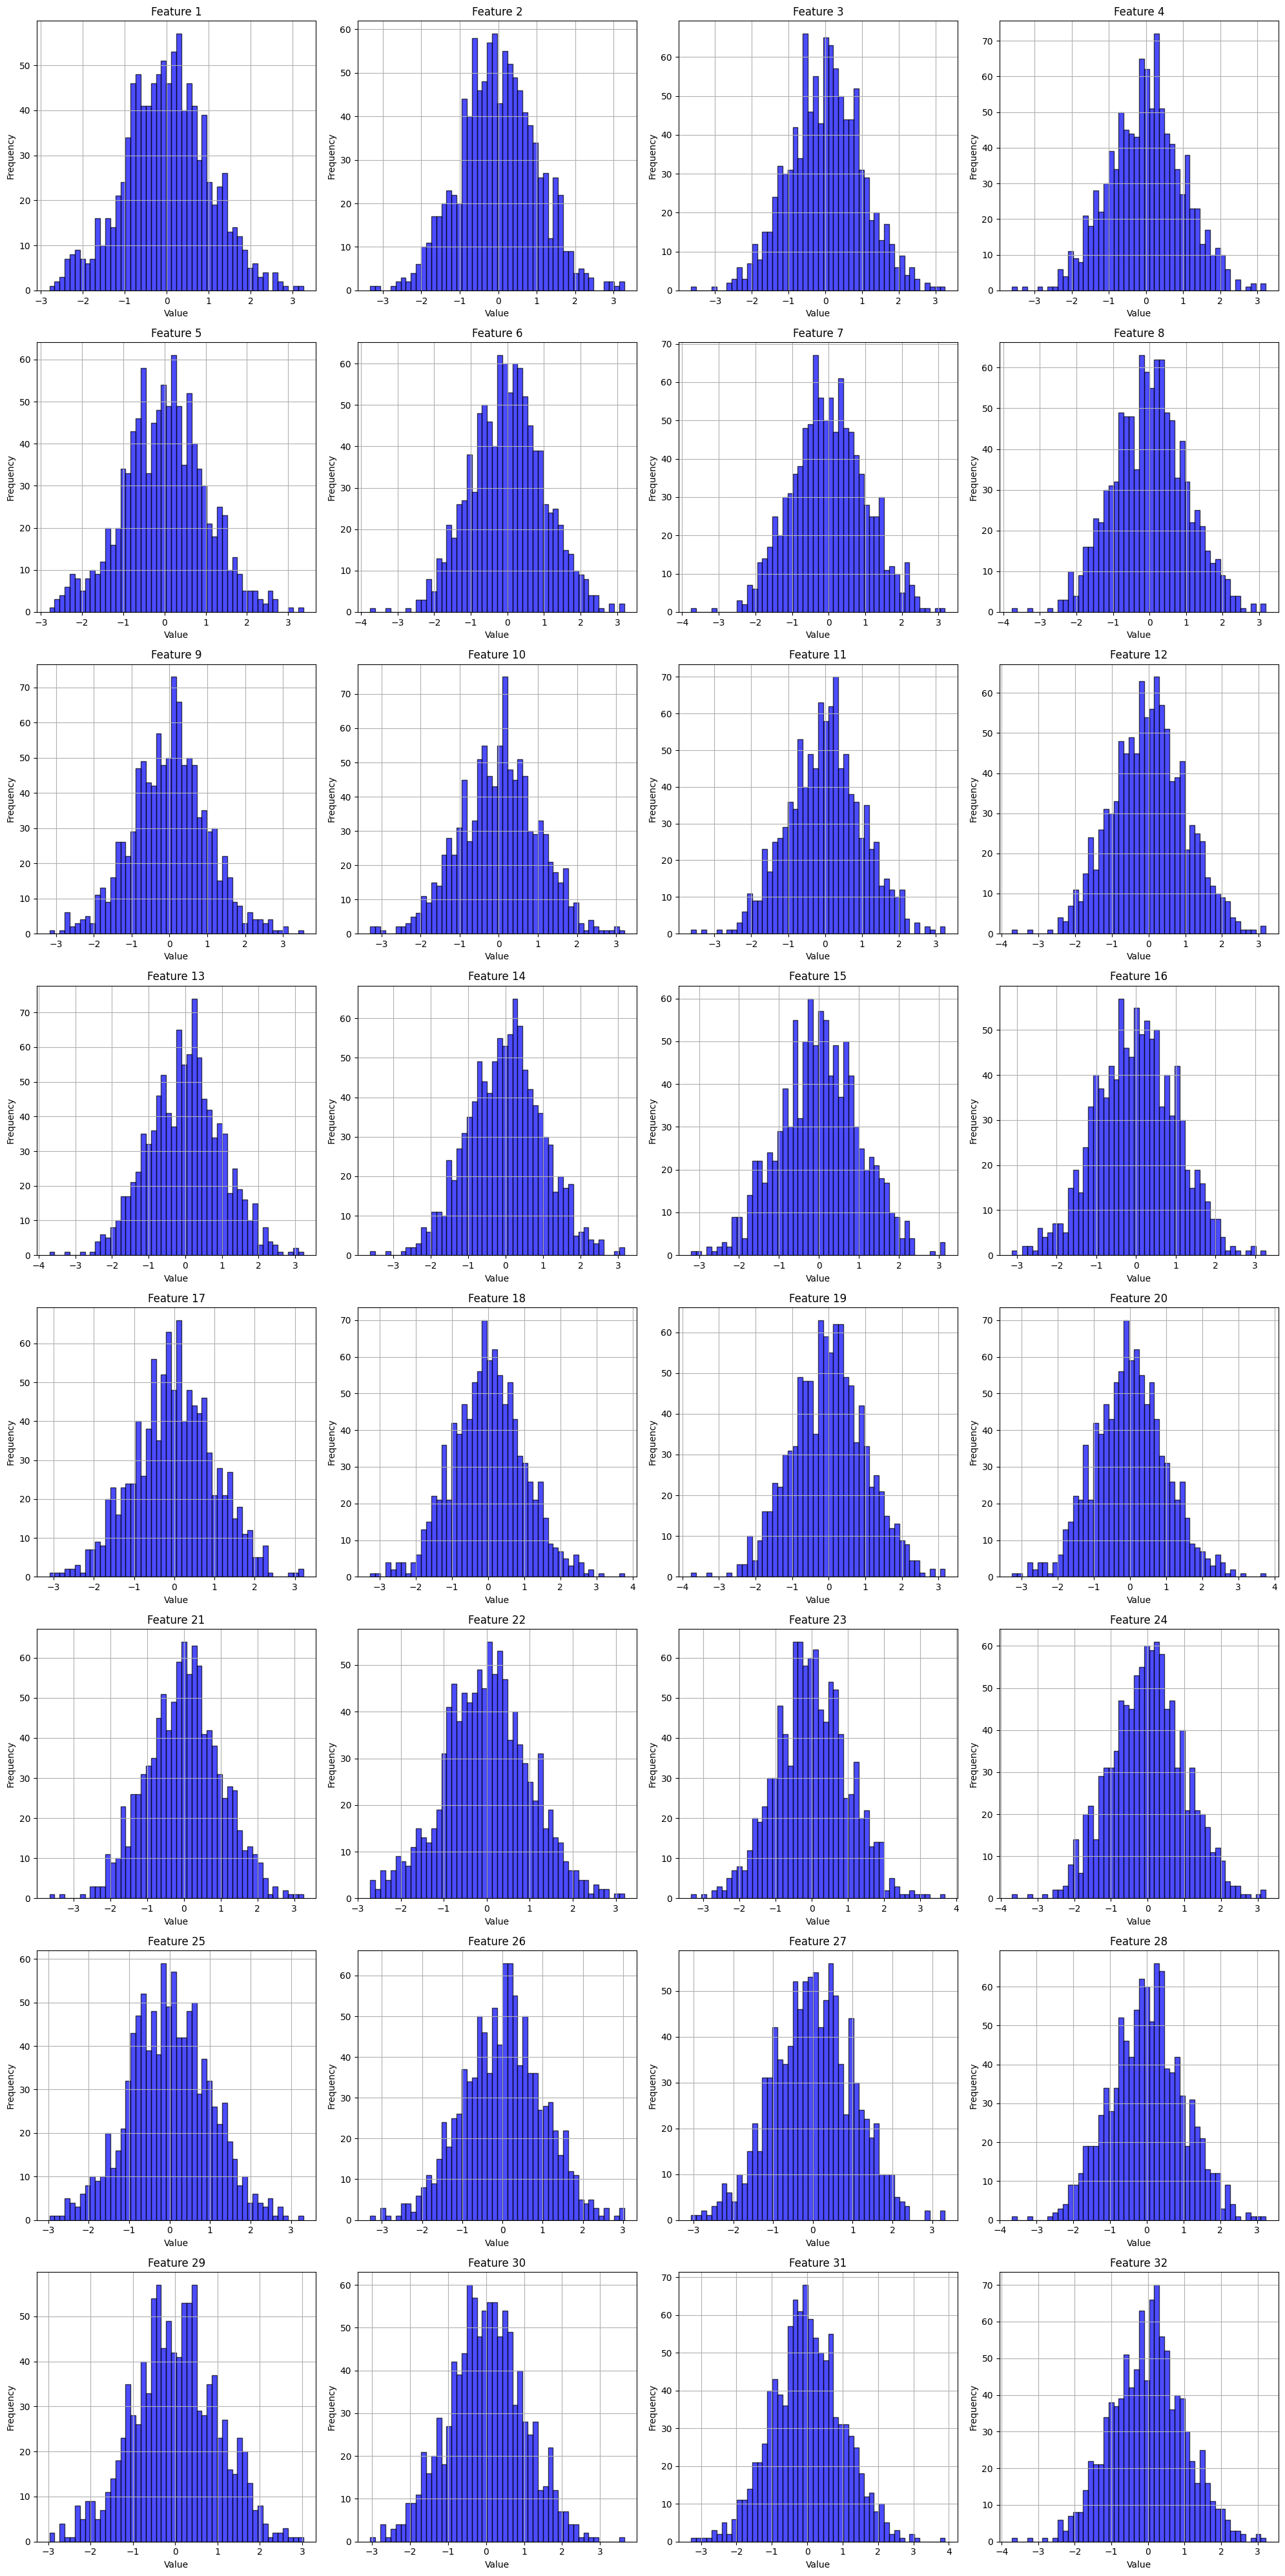

In [18]:
import matplotlib.pyplot as plt

# 获取 train_feature 的维度
num_features = train_feature.shape[0]

# 设置子图的行列数
rows = int(np.ceil(num_features / 4))  # 每行放 4 个子图
cols = 4

# 创建子图
fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
axes = axes.flatten()

# 绘制每个维度的直方图
for i in range(num_features):
    axes[i].hist(train_feature[i, :], bins=50, color='blue', alpha=0.7, edgecolor='black')
    axes[i].set_title(f'Feature {i+1}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
    axes[i].grid(True)

# 如果子图多于特征数，隐藏多余的子图
for j in range(num_features, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
class Regression(torch.nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, output_dim=1):
        super().__init__()
        self.fc1 = torch.nn.Linear(input_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, output_dim)
        self.relu = torch.nn.ReLU()
        self.dropout = torch.nn.Dropout(0.2)
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [ ]:
# 首先冻结 ViT 模型的参数
for param in vit_model.parameters():
    param.requires_grad = False
regression = Regression().to('cuda')

# 设置优化器和损失函数
criterion = torch.nn.MSELoss()
optimizer = torch.optim.AdamW(regression.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=40, gamma=0.1)

In [ ]:
num_epochs = 100
avg_loss_list = []
avf_val_loss_list = []
for epoch in range(num_epochs):
    regression.train()
    total_loss = 0
    for i, data in enumerate(data_loader_train):
        images, labels = data
        images = images.float().to('cuda')
        labels = labels.float().to('cuda')
        
        optimizer.zero_grad()
        
        with torch.no_grad():
            features = vit_model(images)  # 提取特征，不计算梯度
        # features = vit_model(images)
        outputs = regression(features)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
        if i % 10 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(data_loader_train)}], Loss: {loss.item():.4f}")
    
    avg_loss = total_loss / len(data_loader_train)
    print(f"Epoch [{epoch+1}/{num_epochs}], Average Loss: {avg_loss:.4f}")
    
    final_preds = []
    final_labels = []
    
    regression.eval()
    pre_avg_val_loss = 100
    val_loss = 0
    with torch.no_grad():
        tmp_preds = []
        tmp_labels = []
        for data in data_loader_val:
            images, labels = data
            images = images.float().to('cuda')
            labels = labels.float().to('cuda')
            
            features = vit_model(images)
            outputs = regression(features)
            loss = criterion(outputs, labels)
            
            tmp_preds.extend(outputs.cpu().numpy())
            tmp_labels.extend(labels.cpu().numpy())
            val_loss += loss.item()
                
    avg_val_loss = val_loss / len(data_loader_val)
    if avg_val_loss < pre_avg_val_loss:
        final_preds = tmp_preds
        final_labels = tmp_labels
        pre_avg_val_loss = avg_val_loss
    print(f"Validation Loss: {avg_val_loss:.4f}")
    avg_loss_list.append(avg_loss)
    avf_val_loss_list.append(avg_val_loss)

Epoch [1/100], Step [1/2], Loss: 0.2398
Epoch [1/100], Average Loss: 0.1923
Validation Loss: 0.2319
Epoch [2/100], Step [1/2], Loss: 0.1512
Epoch [2/100], Average Loss: 0.1418
Validation Loss: 0.2193
Epoch [3/100], Step [1/2], Loss: 0.0849
Epoch [3/100], Average Loss: 0.0926
Validation Loss: 0.1270
Epoch [4/100], Step [1/2], Loss: 0.0875
Epoch [4/100], Average Loss: 0.0930
Validation Loss: 0.0855
Epoch [5/100], Step [1/2], Loss: 0.1055
Epoch [5/100], Average Loss: 0.0990
Validation Loss: 0.0857
Epoch [6/100], Step [1/2], Loss: 0.0998
Epoch [6/100], Average Loss: 0.0936
Validation Loss: 0.1251
Epoch [7/100], Step [1/2], Loss: 0.0787
Epoch [7/100], Average Loss: 0.0770
Validation Loss: 0.1591
Epoch [8/100], Step [1/2], Loss: 0.0833
Epoch [8/100], Average Loss: 0.0848
Validation Loss: 0.1460
Epoch [9/100], Step [1/2], Loss: 0.0510
Epoch [9/100], Average Loss: 0.0581
Validation Loss: 0.1114
Epoch [10/100], Step [1/2], Loss: 0.0961
Epoch [10/100], Average Loss: 0.0785
Validation Loss: 0.091

In [12]:
len(dataset_train.target_list)

32

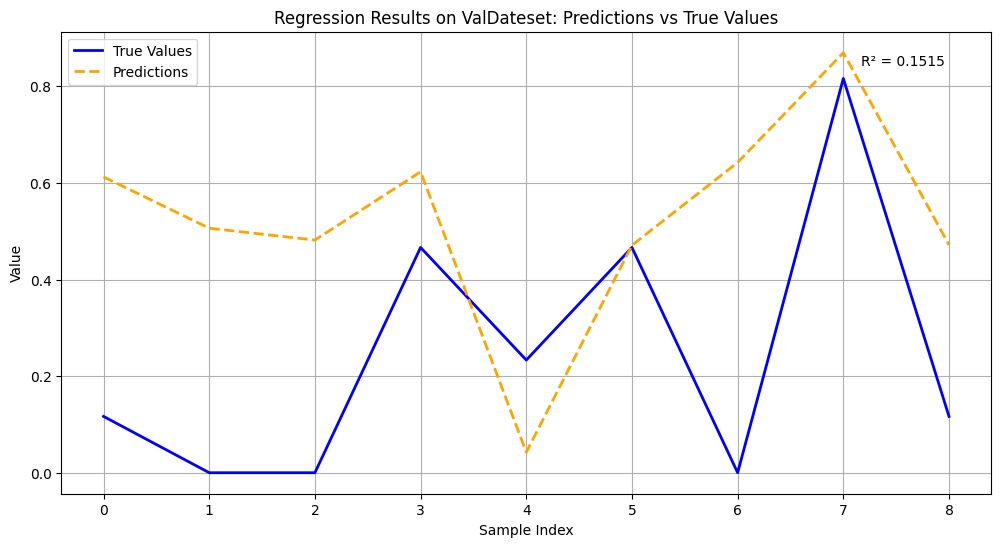

Mean Squared Error: 0.1485
Mean Absolute Error: 0.3207
R² Score: 0.1515


In [23]:
import matplotlib.pyplot as plt
import numpy as np

# 在验证集上收集预测结果
regression.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for data in data_loader_val:
        images, labels = data
        images = images.float().to('cuda')
        labels = labels.float().to('cuda')
        
        features = vit_model(images)
        outputs = regression(features)
        
        # 将预测值和真实值移到CPU并转换为numpy数组
        all_preds.extend(outputs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 转换为numpy数组
# all_preds = np.array(final_preds)
# all_labels = np.array(final_labels)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 绘制预测值和真实值的对比图（同一x, y轴）
plt.figure(figsize=(12, 6))
plt.plot(all_labels, label='True Values', color='blue', linewidth=2)
plt.plot(all_preds, label='Predictions', color='orange', linestyle='--', linewidth=2)

plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Regression Results on ValDateset: Predictions vs True Values')
plt.legend(loc='upper left')

# 添加R²分数
r2 = np.corrcoef(all_labels.flatten(), all_preds.flatten())[0, 1]**2
plt.text(0.95, 0.95, f'R² = {r2:.4f}', transform=plt.gca().transAxes, 
         horizontalalignment='right', verticalalignment='top')

plt.grid(True)
plt.show()

# 计算和打印评估指标
mse = np.mean((all_preds - all_labels) ** 2)
mae = np.mean(np.abs(all_preds - all_labels))
print(f'Mean Squared Error: {mse:.4f}')
print(f'Mean Absolute Error: {mae:.4f}')
print(f'R² Score: {r2:.4f}')

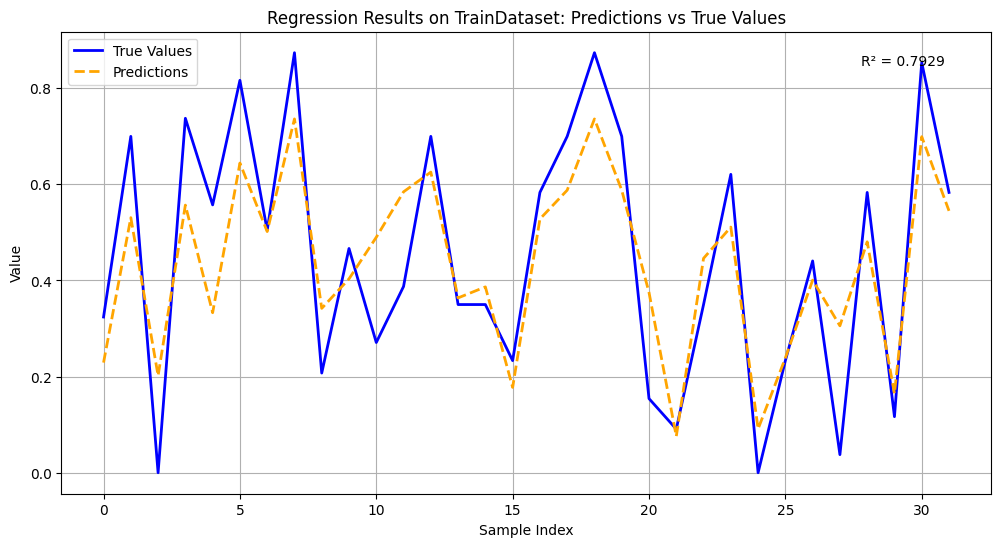

Mean Squared Error: 0.0177
Mean Absolute Error: 0.1120
R² Score: 0.7929


In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 在验证集上收集预测结果
regression.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for data in data_loader_train:
        images, labels = data
        images = images.float().to('cuda')
        labels = labels.float().to('cuda')
        
        features = vit_model(images)
        outputs = regression(features)
        
        # 将预测值和真实值移到CPU并转换为numpy数组
        all_preds.extend(outputs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 转换为numpy数组
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 绘制预测值和真实值的对比图（同一x, y轴）
plt.figure(figsize=(12, 6))
plt.plot(all_labels, label='True Values', color='blue', linewidth=2)
plt.plot(all_preds, label='Predictions', color='orange', linestyle='--', linewidth=2)

plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Regression Results on TrainDataset: Predictions vs True Values')
plt.legend(loc='upper left')

# 添加R²分数
r2 = np.corrcoef(all_labels.flatten(), all_preds.flatten())[0, 1]**2
plt.text(0.95, 0.95, f'R² = {r2:.4f}', transform=plt.gca().transAxes, 
         horizontalalignment='right', verticalalignment='top')

plt.grid(True)
plt.show()

# 计算和打印评估指标
mse = np.mean((all_preds - all_labels) ** 2)
mae = np.mean(np.abs(all_preds - all_labels))
print(f'Mean Squared Error: {mse:.4f}')
print(f'Mean Absolute Error: {mae:.4f}')
print(f'R² Score: {r2:.4f}')